In [16]:
# -*- coding: utf-8 -*-
from turtle import title
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tempfile
import os
from ansys.aedt.core import generate_unique_name
from ansys.aedt.core import Desktop, Hfss, constants

In [17]:
tmpfold = tempfile.gettempdir()

temp_folder = os.path.join(
    tmpfold,
    generate_unique_name("Antenna")
)

if not os.path.exists(temp_folder):
    os.mkdir(temp_folder)

non_graphical = os.getenv(
    "PYAEDT_NON_GRAPHICAL",
    "False"
).lower() in ("true", "1", "t")

d = Desktop(
    "2025.1",
    non_graphical=non_graphical,
    new_desktop=True
)



PyAEDT INFO: Python version 3.10.18 | packaged by conda-forge | (main, Jun  4 2025, 14:42:04) [MSC v.1943 64 bit (AMD64)].
PyAEDT INFO: PyAEDT version 0.17.1.
PyAEDT INFO: Initializing new Desktop session.
PyAEDT INFO: Log on console is enabled.
PyAEDT INFO: Log on file C:\Users\LUIS~1.COS\AppData\Local\Temp\pyaedt_luis.costa_bc8e3c31-820b-4f6e-8c2b-188524470fc7.log is enabled.
PyAEDT INFO: Log on AEDT is enabled.
PyAEDT INFO: Debug logger is disabled. PyAEDT methods will not be logged.
PyAEDT INFO: Launching PyAEDT with gRPC plugin.
PyAEDT INFO: New AEDT session is starting on gRPC port 53898.
PyAEDT INFO: Electronics Desktop started on gRPC port: 53898 after 18.18921685218811 seconds.
PyAEDT INFO: AEDT installation Path C:\Program Files\ANSYS Inc\v251\AnsysEM
PyAEDT INFO: Ansoft.ElectronicsDesktop.2025.1 version started with process ID 16784.


In [18]:
x_sub = 20
y_sub = 28
h = 0.165
r = 10
w = 0.5

perc = 0.5
l = y_sub * perc
h_cut = (r*2) - (y_sub - l)



hfss = Hfss(solution_type="Modal")
hfss.modeler.model_units = "cm"

p = hfss.modeler.primitives

PyAEDT INFO: Python version 3.10.18 | packaged by conda-forge | (main, Jun  4 2025, 14:42:04) [MSC v.1943 64 bit (AMD64)].
PyAEDT INFO: PyAEDT version 0.17.1.
PyAEDT INFO: Returning found Desktop session with PID 16784!
PyAEDT INFO: Project Project20 has been created.
PyAEDT INFO: No design is present. Inserting a new design.
PyAEDT INFO: Added design 'HFSS_3XK' of type HFSS.
PyAEDT INFO: Aedt Objects correctly read
PyAEDT INFO: Modeler class has been initialized! Elapsed time: 0m 0sec


In [19]:

substrate = p.create_box(
    [-x_sub/2,-y_sub/2,0],
    [x_sub,y_sub,h],
    material="FR4_epoxy",
    name="substrate"
)

gnd = p.create_rectangle(
    constants.AXIS.Z,
    [-x_sub/2, -y_sub/2,0] ,
    [x_sub,l],
    "ground"
)

path = p.create_rectangle(
    constants.AXIS.Z,
    [-w/2, -y_sub/2, h],
    [w, l],
    "path",
)   

port = p.create_rectangle(
    constants.AXIS.Y,
    [-w/2, -y_sub/2, 0],
    [h, w],  
    "port",
)

monopole = p.create_circle(
    constants.AXIS.Z,
    [0, -y_sub/2+l+r-0.025,h],
    r,
    50,
    "monopole"
)

if h_cut > 0:
    cut = p.create_rectangle(
        constants.AXIS.Z,
        [-x_sub/2, y_sub/2, h],
        [x_sub, h_cut],  
        "cut",
    )
    p.subtract(monopole, cut)
    p.delete(cut)
    
monopole_unite = p.unite([monopole, path])


PyAEDT INFO: Materials class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Deleted 1 Objects: cut.
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Union of 2 objects has been executed.


In [20]:
hfss.lumped_port(
    assignment=port.name,                 
    reference=port,
    integration_line=hfss.AxisDir.ZNeg,    
    impedance=50,
    name=generate_unique_name("port"),
    renormalize=False,
    terminals_rename=False
)

hfss.assign_perfect_e(
    gnd.name
)

hfss.assign_perfect_e(
    monopole.name
)

PyAEDT INFO: Boundary Lumped Port port_1RDX3L has been created.
PyAEDT INFO: Boundary Perfect E PerfectE_ground has been created.
PyAEDT INFO: Boundary Perfect E PerfectE_NewObject_U1DM8R has been created.


In [21]:
my_plot = hfss.plot(show=False, plot_air_objects=False)
my_plot.show_axes = False
my_plot.show_grid = False
my_plot.isometric_view = True
my_plot.plot(
    os.path.join(hfss.working_directory, "monopole.jpg")    
)

setup = hfss.create_setup("MySetup")

PyAEDT INFO: Parsing C:/Users/luis.costa/Documents/Ansoft/Project20.aedt.
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Post class has been initialized! Elapsed time: 0m 0sec


Widget(value='<iframe src="http://localhost:53422/index.html?ui=P_0x178881329b0_1&reconnect=auto" class="pyvis…

In [22]:
def SingleFrequency(
    freq,
    maxPasses,
    maxDeltaS= 0.01,
    name="MySetup"
):
    hfss.create_open_region(frequency=freq)
    setup.props["Frequency"] = freq
    setup.props["MaximumPasses"] = maxPasses
    setup.props["MaxDeltaS"] =maxDeltaS
    setup.props["UseIterativeSolver"] = True
    setup.props["SaveRadFieldsOnly"] = True
    setup.props["RadiationSetup"] = "3D"
    setup.props["ComputeFarFields"] = True

SingleFrequency("1500MHz", 30,0.02)

PyAEDT INFO: Open Region correctly created.
PyAEDT INFO: Project Project20 Saved correctly


In [23]:
def LinearCountSweep(
    fStart,
    fStop,
    freqPonts=401,
    units="MHz",
    saveFields=True,
    saveRadFields=True
):
    sweep = hfss.create_linear_count_sweep(
        setup=setup.name,
        units=units,
        start_frequency=fStart,
        stop_frequency=fStop,
        num_of_freq_points = freqPonts,
        name= "sweep",
        sweep_type="Interpolating",
        save_fields=saveFields,
        save_rad_fields=saveRadFields
    )
LinearCountSweep(300,1500)


PyAEDT INFO: Parsing C:/Users/luis.costa/Documents/Ansoft/Project20.aedt.
PyAEDT INFO: File C:/Users/luis.costa/Documents/Ansoft/Project20.aedt correctly loaded. Elapsed time: 0m 0sec
PyAEDT INFO: aedt file load time 0.15448665618896484
PyAEDT INFO: Linear count sweep sweep has been correctly created.


In [24]:
def SaveAnalyseSetup(
    nameFolder= "Monopole.aedt",
    setup="MySetup"
):
    hfss.save_project(os.path.join(temp_folder, nameFolder))
    hfss.analyze_setup(setup)

SaveAnalyseSetup("Monopole.aedt")

PyAEDT INFO: Project Monopole Saved correctly
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT INFO: Solving design setup MySetup
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT INFO: Design setup MySetup solved correctly in 0.0h 1.0m 24.0s


In [25]:

solutions = hfss.post.get_solution_data(
    expressions=hfss.get_traces_for_plot(category="dB(S")
)

solutions.enable_pandas_output = True

S_Real = solutions._init_solution_data_real()
index = 0
S_real1 = S_Real[list(S_Real.keys())[index]]
listaReal = []
listaReal2 = []
dataVazioGap = {}
dfRealGap = pd.DataFrame(dataVazioGap)
for i,c in S_real1.items():
    listaReal.append(float(i[0]))
    listaReal2.append(float(c))
dfRealGap.insert(0, "Frequency [MHz]", listaReal, True)
dfRealGap.insert(1, "|$S_{11}$| [dB]", listaReal2, True)
indexValueMin = dfRealGap['|$S_{11}$| [dB]'].idxmin()

dfRealGap.to_csv('S11_Gap.csv')

PyAEDT INFO: Solution Data Correctly Loaded.


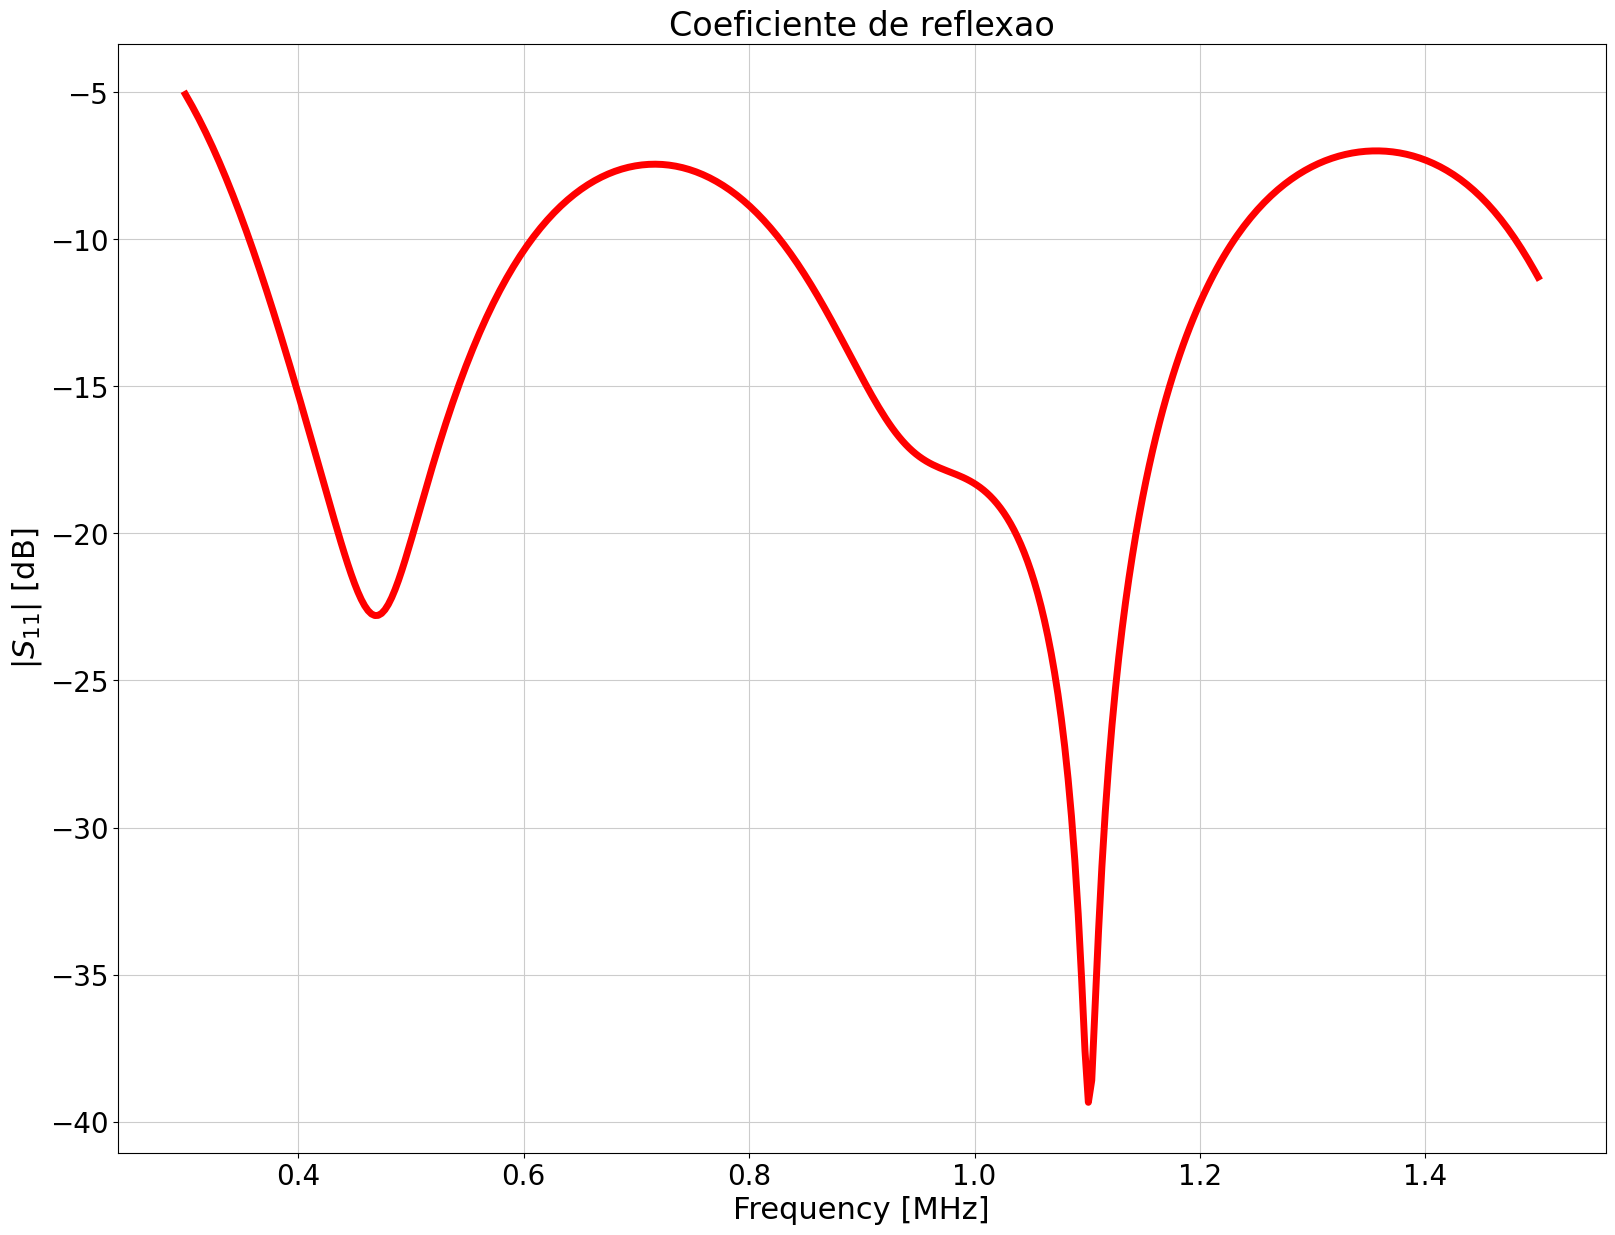

In [26]:
def Grafico(
    df,
    title,
    nameX='Frequency [MHz]',
    nameY='Result',
    colorGraf='red'
):
    valorEixoY = df[nameY].to_numpy()
    valorEixoX = df[nameX].to_numpy()
    fig, ax = plt.subplots()
    ax.plot(valorEixoX, valorEixoY, color='red', linewidth = 5)
    ax.set_xlabel(nameX, fontsize = 22)
    ax.set_ylabel(nameY, fontsize = 22)
    plt.tick_params(axis='both', which='major', labelsize=20)
    plt.title(title, fontsize=24)
    plt.show()

Grafico(
    dfRealGap,
    "Coeficiente de reflexao",
    "Frequency [MHz]",
    "|$S_{11}$| [dB]",
)

In [27]:
new_report = hfss.post.reports_by_category.far_field(
    "GainTotal",
    hfss.nominal_adaptive,
    "3D"
)
variations = hfss.available_variations.nominal_w_values_dict
variations["Theta"] = ["All"]
variations["Phi"] = ["All"]
variations["Freq"] = ["1500MHz"]

In [28]:
new_report.primary_sweep ="Theta"
new_report.secondary_sweep ="Phi"
new_report.far_field_sphere = "3D"
new_report.variations = variations
solutions = new_report.get_solution_data()

PyAEDT INFO: Solution Data Correctly Loaded.


[-5.051861088148939,
 -5.086188660807462,
 -5.225582417645346,
 -5.4675774350071205,
 -5.806341782416275,
 -6.229834236290524,
 -6.714982613531303,
 -7.220685475568561,
 -7.680511048855392,
 -8.002210676153329,
 -8.086648125589177,
 -7.869734515121332,
 -7.359433564545022,
 -6.629318894755254,
 -5.775991135715048,
 -4.881784846161127,
 -4.001924020161907,
 -3.1677973343052006,
 -2.39458066272649,
 -1.6877448234806578,
 -1.0473870392306068,
 -0.47082008357939886,
 0.0459622474768106,
 0.5074829979118924,
 0.9183556687748162,
 1.2830661801520624,
 1.6058686939919966,
 1.8907426955892537,
 2.1413822400360685,
 2.3612013543677692,
 2.5533468517304754,
 2.7207138451650428,
 2.8659614807044607,
 2.991527639255101,
 3.099642028613276,
 3.192337450133173,
 3.271459218937526,
 3.3386728201710243,
 3.3954699391701797,
 3.4431730326668637,
 3.4829386217944474,
 3.5157594900769924,
 3.5424659622722428,
 3.563726423670015,
 3.580047215428006,
 3.591772011968781,
 3.599080754638499,
 3.6019881857467

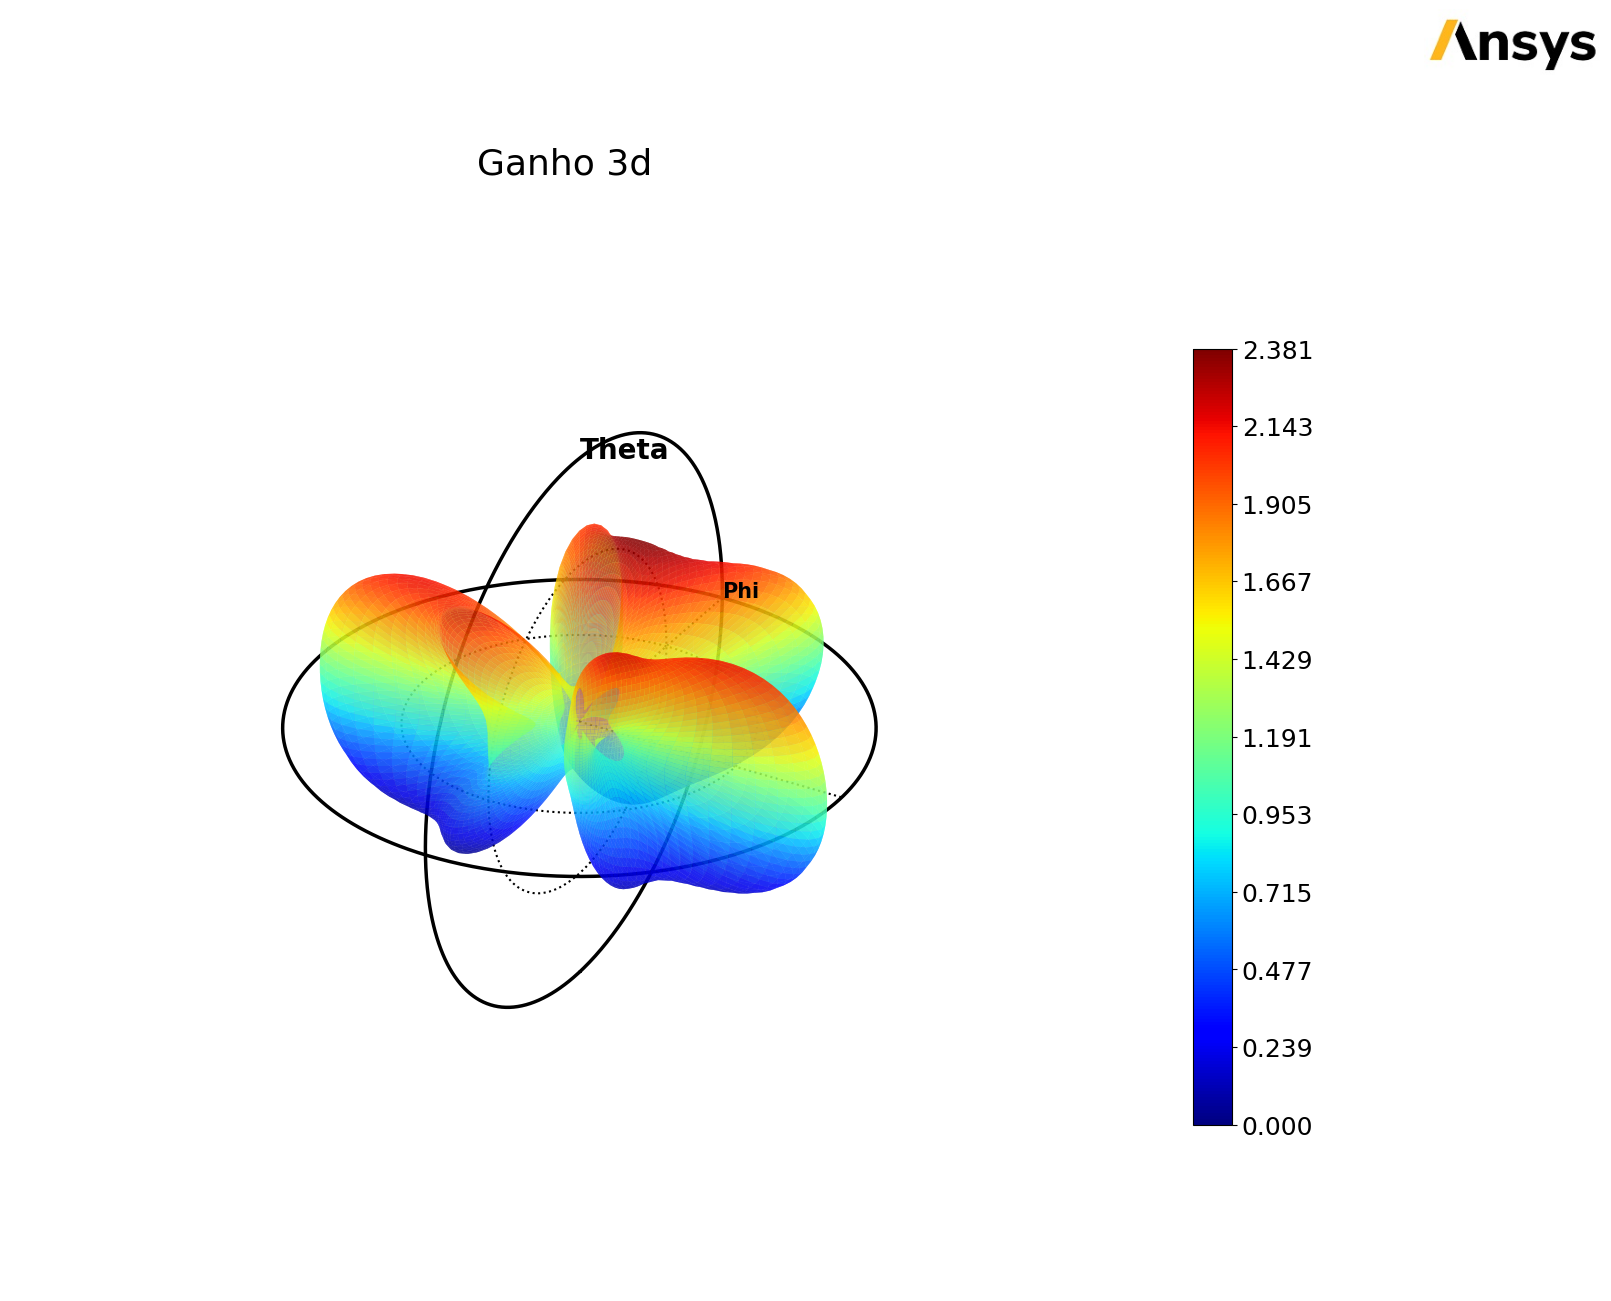

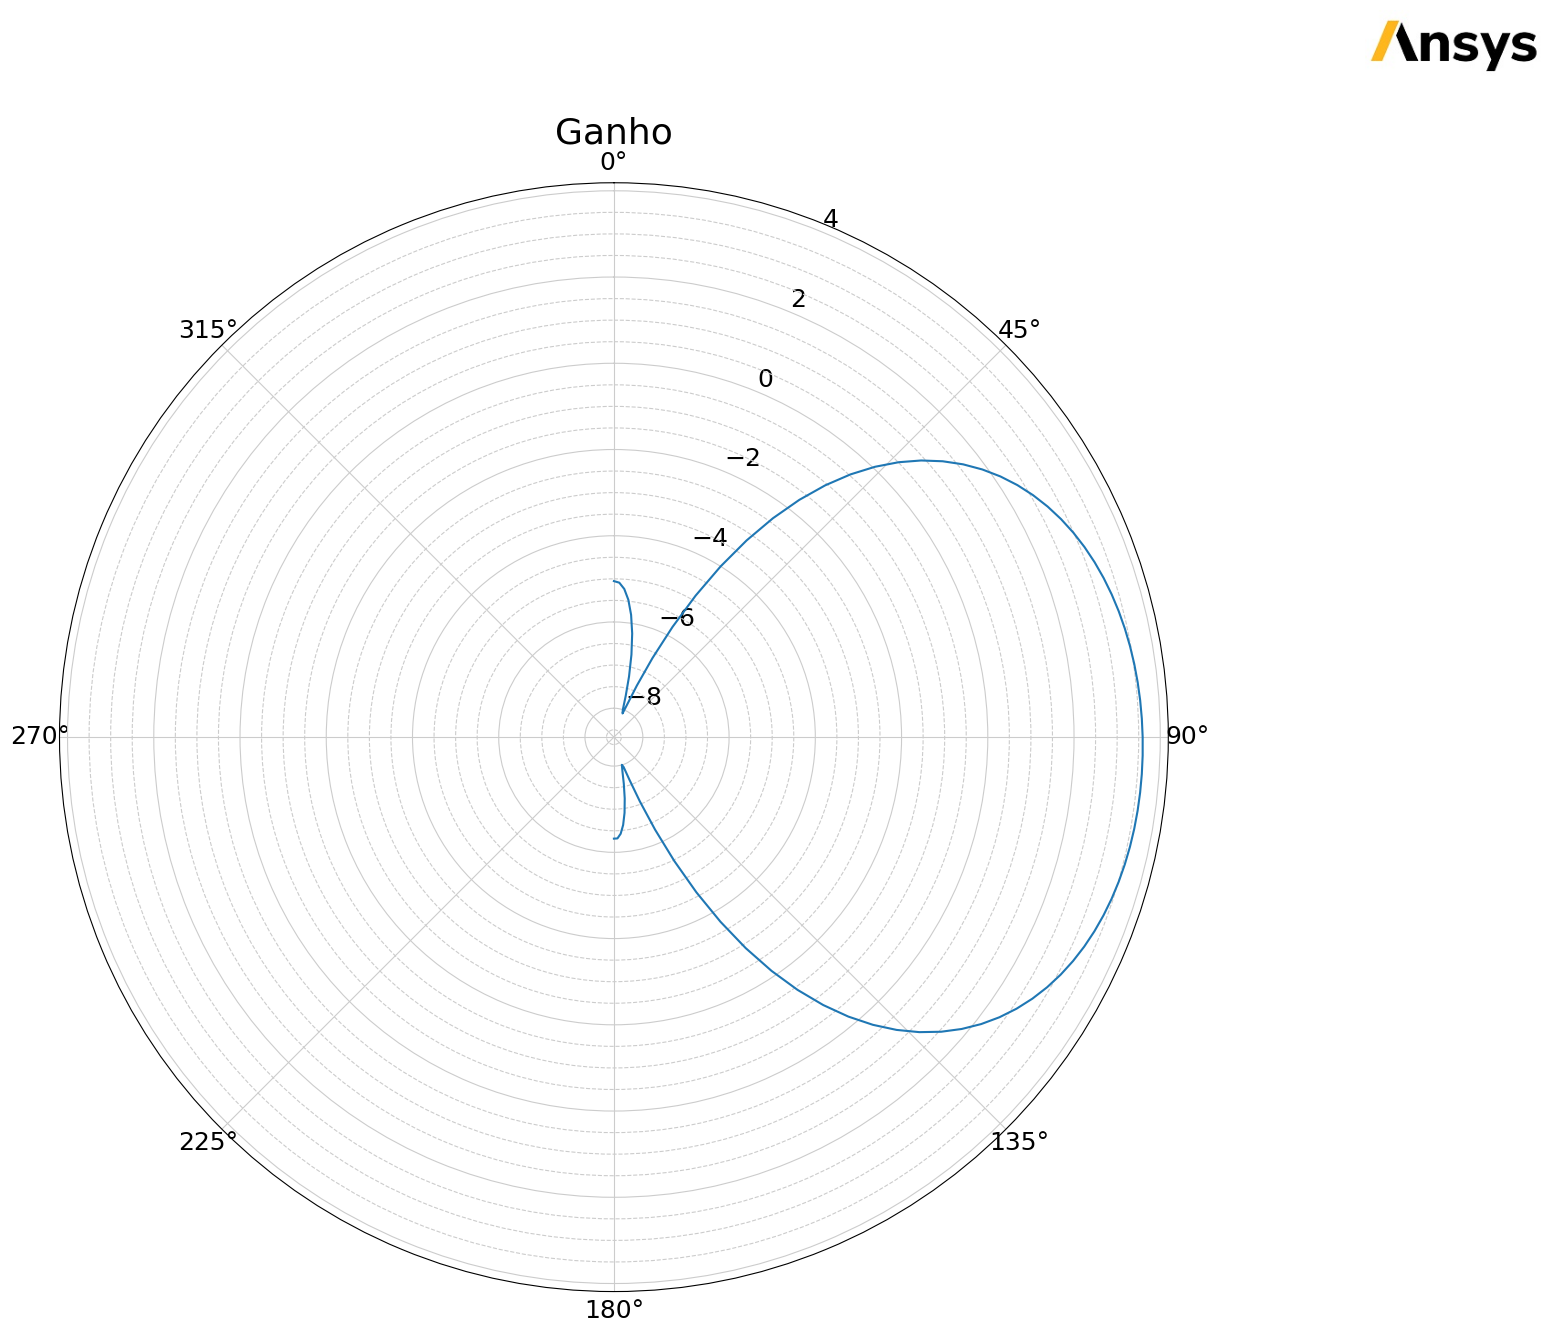

In [29]:
solutions.plot_3d(title="Ganho 3d")

solutions.plot(
     formula="db10",
     is_polar=True,
     show_legend=False,
     title="Ganho"
)

solutions.data_db10()

In [31]:
d.release_desktop()

PyAEDT INFO: Desktop has been released and closed.


True